# 05b · Slotting otimizado (PuLP), reabastecimento e plano de transição
**Objetivo:** escolher **quais SKUs ganham face de picking e em qual face**, para minimizar o custo
anual de separação + reabastecimento. Comparamos três cenários com o **mesmo modelo de custo**:
1. **Atual** — faces na ordem de cadastro (05a).
2. **COI** (*cube-per-order index*, regra prática) — os SKUs mais visitados ganham face, e o mais
   visitado fica na face mais próxima.
3. **Ótimo (PuLP)** — programação inteira: o solver testa todas as combinações.

*EN summary: integer-programming slotting model (PuLP + HiGHS) vs. a COI rule and the current
assignment; replenishment sensitivity; transition plan and payback. Savings go to the cost register.*

In [1]:
import sys
sys.path.insert(0, "../src")
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import pulp
from dcanalysis import save, savefig, log, params, register_saving, PHASE5, ZONE_COLORS

NB = "05b"
P = params()
prod, custo = P["productivity"], P["labor_cost"]
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False})
pd.set_option("display.width", 140)

base = pd.read_csv(PHASE5 / "sku_slotting_base.csv", sep=";", decimal=",")
faces = pd.read_csv(PHASE5 / "pick_faces.csv", sep=";", decimal=",")
print(f"{len(base)} SKUs · {len(faces)} faces")

600 SKUs · 304 faces


## 1. Modelo de custo (o mesmo para todos os cenários)
Para o SKU *i* numa face a *d* metros:

$$C_{i}(d) = V_i \left[ f_i \cdot c^{face}(d) + (1 - f_i) \cdot c^{pulmão}_i \right] + P_i \cdot f_i \cdot c^{reab}_i$$

e sem face: $C_i^{0} = V_i \cdot c^{pulmão}_i$.
- $V_i$ = visitas/ano · $P_i$ = paletes/ano · $c$ = custo de uma visita/reabastecimento (05a)
- $f_i$ = fração das visitas que a face consegue atender. Na 05a vimos que ela **cai com o giro**
  (face de 1 palete esvazia rápido): usamos a curva observada (73% → 55%) em vez de uma média —
  assim o modelo não superestima o ganho de colocar itens de giro alto na face.

In [2]:
v_a, v_r = prod["walk_speed_m_s"], prod["reach_truck_speed_m_s"]
t_pick = prod["pick_time_per_line_s"]
c_p, c_r = custo["picker_brl_h"] / 3600, custo["reach_truck_brl_h"] / 3600

# Curva fração-na-face × giro (medianas dos quartis da 05a). Interpolação em escala log do giro.
curva_giro = np.array([2.0, 7.13, 21.12, 89.32])        # paletes/ano (mediana de cada quartil)
curva_frac = np.array([0.73, 0.65, 0.61, 0.55])          # fração atendida pela face
def frac_face(paletes_ano):
    return np.interp(np.log1p(paletes_ano), np.log1p(curva_giro), curva_frac)

def custo_face(d):
    return (2 * d / v_a + t_pick) * c_p

base["f"] = frac_face(base.paletes_ano)
base["c_sem_face"] = base.visitas_ano * base.custo_visita_pulmao

def custo_sku(df, dist):
    """Custo anual do SKU com face a `dist` metros (vetorizado)."""
    return (df.visitas_ano * (df.f * custo_face(dist) + (1 - df.f) * df.custo_visita_pulmao)
            + df.paletes_ano * df.f * df.custo_reab_palete)

def custo_cenario(df, dist_col):
    """Custo total de um cenário: SKUs com face usam custo_sku; sem face, c_sem_face."""
    tem = df[dist_col].notna()
    return np.where(tem, custo_sku(df, df[dist_col].fillna(0)), df.c_sem_face)

base["custo_atual"] = custo_cenario(base, "dist_face_m")

## 2. Regra prática COI
Por zona: ordena SKUs ativos por visitas/ano (decrescente) e faces por distância (crescente);
o 1º SKU vai para a 1ª face, e assim por diante, até acabarem as faces.

In [3]:
ativos = base[(base.status == "ACTIVE") & (base.visitas_ano > 0)]
coi = []
for z, fz in faces.groupby("zone"):
    sk = ativos[ativos.zone == z].sort_values("visitas_ano", ascending=False).head(len(fz))
    fz = fz.sort_values("dist_m").head(len(sk))
    coi.append(pd.DataFrame({"sku_id": sk.sku_id.values, "face_coi": fz.location_id.values,
                             "dist_coi": fz.dist_m.values}))
base = base.merge(pd.concat(coi), on="sku_id", how="left")
base["custo_coi"] = custo_cenario(base, "dist_coi")

## 3. Modelo de otimização (PuLP)
**Variável:** $x_{ij} = 1$ se o SKU *i* fica na face *j*.

$$\min \sum_{i,j} C_i(d_j)\, x_{ij} + \sum_i C_i^0 \Big(1 - \sum_j x_{ij}\Big)$$

**Restrições:**
- cada face recebe no máximo 1 SKU: $\sum_i x_{ij} \le 1$
- cada SKU ocupa no máximo 1 face: $\sum_j x_{ij} \le 1$
- SKU só vai para face da **sua zona de temperatura** (modelo resolvido por zona)
- SKUs descontinuados não recebem face

É um problema de designação (*assignment*); o solver HiGHS resolve em segundos.

In [4]:
def otimizar_zona(z):
    sk = ativos[ativos.zone == z].set_index("sku_id")
    fz = faces[faces.zone == z].set_index("location_id")
    prob = pulp.LpProblem(f"slotting_{z}", pulp.LpMinimize)
    # Variáveis binárias x[i, j]
    x = pulp.LpVariable.dicts("x", [(i, j) for i in sk.index for j in fz.index], cat="Binary")
    # Custo de cada par (SKU, face) calculado de uma vez (matriz SKUs x faces)
    custo_par = {(i, j): float(c) for i in sk.index
                 for j, c in zip(fz.index, custo_sku(sk.loc[[i] * len(fz)].reset_index(drop=True),
                                                     fz.dist_m.values))}
    # Função objetivo: custo com face (onde x=1) + custo sem face (onde o SKU não recebeu nenhuma)
    prob += (pulp.lpSum(custo_par[i, j] * x[i, j] for i in sk.index for j in fz.index)
             + pulp.lpSum(sk.c_sem_face[i] * (1 - pulp.lpSum(x[i, j] for j in fz.index)) for i in sk.index))
    for j in fz.index:                                   # 1 SKU por face
        prob += pulp.lpSum(x[i, j] for i in sk.index) <= 1
    for i in sk.index:                                   # 1 face por SKU
        prob += pulp.lpSum(x[i, j] for j in fz.index) <= 1
    t0 = time.time()
    prob.solve(pulp.HiGHS(msg=False))
    print(f"{z:8s} {len(sk)} SKUs x {len(fz)} faces = {len(x):,} variáveis | "
          f"{pulp.LpStatus[prob.status]} em {time.time() - t0:.1f} s")
    escolha = [(i, j) for (i, j), v in x.items() if v.value() > 0.5]
    return pd.DataFrame(escolha, columns=["sku_id", "face_otima"]).merge(
        fz.dist_m.rename("dist_otima"), left_on="face_otima", right_index=True)

otimo = pd.concat([otimizar_zona(z) for z in faces.zone.unique()])
base = base.merge(otimo, on="sku_id", how="left")
base["custo_otimo"] = custo_cenario(base, "dist_otima")

dry      432 SKUs x 232 faces = 100,224 variáveis | Optimal em 7.6 s


chilled  90 SKUs x 40 faces = 3,600 variáveis | Optimal em 0.1 s
frozen   60 SKUs x 32 faces = 1,920 variáveis | Optimal em 0.1 s


## 4. Comparação dos cenários

In [5]:
def resumo_cenario(df, dist_col, custo_col):
    tem = df[dist_col].notna()
    f = np.where(tem, df.f, 0)
    visitas_face = (df.visitas_ano * f).sum()
    horas_ret = ((df.visitas_ano * (1 - f) * df.descidas_por_visita
                  * (prod["reserve_retrieval_s"] + 2 * df.dist_pulmao_m / v_r)
                  + np.where(tem, df.paletes_ano * f, 0) * (prod["replenish_time_s"] + 2 * df.dist_pulmao_m / v_r))
                 .sum() / 3600)
    dist_km = (df.visitas_ano * (f * 2 * df[dist_col].fillna(0) + (1 - f) * 2 * df.dist_pulmao_m)).sum() / 1000
    return {"custo_ano_R$": df[custo_col].sum(), "visitas_na_face_%": 100 * visitas_face / df.visitas_ano.sum(),
            "horas_retratil_ano": horas_ret, "km_separador_ano": dist_km}

cen = pd.DataFrame({"Atual": resumo_cenario(base, "dist_face_m", "custo_atual"),
                    "COI": resumo_cenario(base, "dist_coi", "custo_coi"),
                    "Ótimo (PuLP)": resumo_cenario(base, "dist_otima", "custo_otimo")}).T
cen["economia_vs_atual_%"] = 100 * (1 - cen["custo_ano_R$"] / cen.loc["Atual", "custo_ano_R$"])
save(cen.reset_index(names="cenario").round(1), "05b_cenarios", out=PHASE5)
# Tabela por SKU com as faces de cada cenário (usada pela simulação da Fase 6)
save(base[["sku_id", "zone", "abc", "visitas_ano", "paletes_ano", "f", "dist_pulmao_m", "descidas_por_visita",
           "dist_face_m", "dist_coi", "dist_otima", "custo_atual", "custo_coi", "custo_otimo"]].round(4),
     "sku_slotting_scenarios", out=PHASE5)
cen.round(1)

,custo_ano_R$,visitas_na_face_%,horas_retratil_ano,km_separador_ano,economia_vs_atual_%
Atual,1129896.8,26.4,7240.1,91242.5,0.0
COI,1053347.6,48.0,6675.3,84668.0,6.8
Ótimo (PuLP),1038398.0,39.4,6652.2,82879.9,8.1


In [6]:
# Por zona: onde está o ganho?
por_zona = base.groupby("zone")[["custo_atual", "custo_coi", "custo_otimo"]].sum()
por_zona["economia_otimo_%"] = 100 * (1 - por_zona.custo_otimo / por_zona.custo_atual)
por_zona.round(1)

,custo_atual,custo_coi,custo_otimo,economia_otimo_%
zone,,,,
chilled,138646.4,135093.3,129888.2,6.3
dry,903540.3,832908.0,824418.4,8.8
frozen,87710.1,85346.2,84091.4,4.1


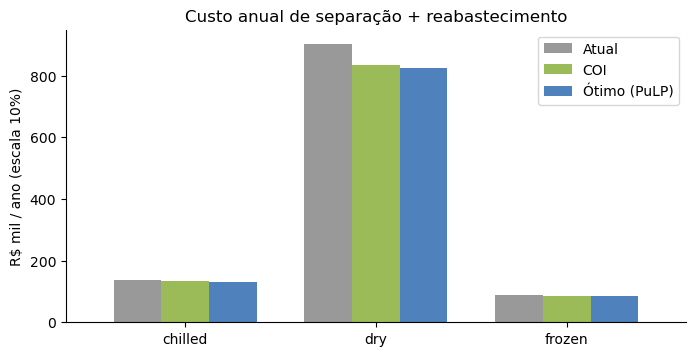

In [7]:
# Barras agrupadas: compara o custo anual dos três cenários em cada zona (poucas categorias, valores absolutos).
fig, ax = plt.subplots(figsize=(8, 3.8))
(por_zona[["custo_atual", "custo_coi", "custo_otimo"]] / 1000).plot.bar(
    ax=ax, color=["#999999", "#9BBB59", "#4F81BD"], width=0.75, rot=0)
ax.set_ylabel("R$ mil / ano (escala 10%)"); ax.set_xlabel("")
ax.legend(["Atual", "COI", "Ótimo (PuLP)"]); ax.set_title("Custo anual de separação + reabastecimento")
savefig(fig, "05b_cenarios_zona", out=PHASE5)

**Leitura:**
- Reorganizar as faces reduz o custo de separação + reabastecimento em **≈8%**; a regra simples COI
  captura **≈7%**. O otimizador rende **~20% a mais de ganho** que a regra prática.
- Por quê: o SKU de giro **muito alto** não é o melhor candidato à face. Um palete baixado do pulmão
  atende muitas linhas dele na mesma noite (a descida da retrátil se dilui), e na face ele exigiria
  reabastecimento o tempo todo. A face rende mais para SKUs com **muitas visitas por palete**
  (muitas linhas pequenas) — exatamente o critério do *cube-per-order index* "de verdade", que
  considera visitas **e** volume. Por isso o ótimo tem menos visitas na face (39%) que o COI (48%)
  e mesmo assim custa menos.
- Mensagem para a gestão: revisar o slotting por **visitas e volume**, não só por "mais vendido".
  O modelo PuLP já está pronto para restrições reais (peso por nível, família de produto,
  segregação de químicos de alimentos, mais de uma face por SKU).

## 5. Reabastecimento: quanto vale manter a face abastecida?
Hoje só 55–73% das visitas a SKUs com face são atendidas pela face (05a). Com o slotting ótimo
fixo, simulamos o custo se a face atendesse 70%, 85% e 95% das visitas — o que se obtém com
gatilho de reabastecimento por mínimo (ex.: repor quando a face tiver < 1 dia de demanda) e
reabastecimento antecipado no turno anterior à separação.

In [8]:
sens = []
fr_atual = base.f.copy()
for alvo in [None, 0.70, 0.85, 0.95]:
    base["f"] = fr_atual if alvo is None else np.maximum(fr_atual, alvo)
    c = custo_cenario(base, "dist_otima").sum()
    sens.append({"fração atendida pela face": "atual (curva 05a)" if alvo is None else f"{alvo:.0%}",
                 "custo_ano_R$": c})
base["f"] = fr_atual
sens = pd.DataFrame(sens)
sens["economia_adicional_R$"] = sens["custo_ano_R$"].iloc[0] - sens["custo_ano_R$"]
save(sens.round(0), "05b_reabastecimento_sensibilidade", out=PHASE5)
sens.round(0)

,fração atendida pela face,custo_ano_R$,economia_adicional_R$
0,atual (curva 05a),1038398.0,0.0
1,70%,999489.0,38909.0
2,85%,950241.0,88157.0
3,95%,917396.0,121002.0


**Leitura:** cada ponto percentual a mais de visitas atendidas na face tira uma descida de palete
da retrátil. Política proposta de reabastecimento das faces:
- **mínimo** = 1 dia de demanda do SKU (repor ao atingir) · **máximo** = 1 palete (capacidade da face);
- SKUs com mais de ~1 palete/dia: reabastecimento **programado** antes do turno de separação
  (noite), não sob demanda;
- indicador de controle: **% das visitas atendidas pela face** por SKU (meta ≥ 85%).

## 6. Plano de transição e retorno

In [9]:
muda = base[(base.face_otima.notna()) & (base.face_otima != base.pick_face_location_id)].copy()
sai = base[(base.pick_face_location_id.notna()) & (base.face_otima.isna())]
movimentos = len(muda) + len(sai)          # entra/troca de face + libera face
horas_trans = movimentos * prod["relocation_time_s"] / 3600
custo_trans = horas_trans * custo["reach_truck_brl_h"]
economia = base.custo_atual.sum() - base.custo_otimo.sum()
payback_dias = custo_trans / (economia / 365)
print(f"Remanejamentos: {movimentos} ({len(muda)} SKUs entram/trocam de face, {len(sai)} liberam face)")
print(f"Esforço: {horas_trans:.0f} h de retrátil ≈ R$ {custo_trans:,.0f} | economia: R$ {economia:,.0f}/ano "
      f"| payback ≈ {payback_dias:.1f} dias")

# Ondas: começar pelos remanejamentos de maior ganho individual
muda["ganho"] = muda.custo_atual - muda.custo_otimo
muda = muda.sort_values("ganho", ascending=False)
muda["ganho_acum_%"] = 100 * muda.ganho.cumsum() / muda.ganho.sum()
n_onda1 = int((muda["ganho_acum_%"] <= 80).sum()) + 1
print(f"Onda 1: {n_onda1} remanejamentos ({n_onda1 / len(muda):.0%}) capturam 80% do ganho "
      f"— curva A: {muda.head(n_onda1).abc.eq('A').mean():.0%} deles")
plano = muda[["sku_id", "sku_code", "zone", "abc", "visitas_ano", "pick_face_location_id",
              "face_otima", "ganho"]].round(2)
plano["onda"] = np.where(np.arange(len(plano)) < n_onda1, 1, 2)
save(plano, "05b_plano_transicao", out=PHASE5)
plano.head(10)

Remanejamentos: 458 (304 SKUs entram/trocam de face, 154 liberam face)
Esforço: 38 h de retrátil ≈ R$ 1,718 | economia: R$ 91,499/ano | payback ≈ 6.9 dias
Onda 1: 103 remanejamentos (34%) capturam 80% do ganho — curva A: 55% deles


,sku_id,sku_code,zone,abc,visitas_ano,pick_face_location_id,face_otima,ganho,onda
383,383,SKU000384,dry,A,11111.5,NaN,769.0,3912.11,1
446,446,SKU000447,dry,A,8902.0,NaN,768.0,3901.66,1
104,104,SKU000105,dry,B,4994.5,624.0,792.0,3285.99,1
297,297,SKU000298,dry,A,6730.0,NaN,780.0,3023.59,1
272,272,SKU000273,dry,A,4405.0,NaN,13.0,2161.06,1
369,369,SKU000370,dry,A,4880.5,NaN,793.0,2052.50,1
376,376,SKU000377,dry,A,4706.0,NaN,817.0,2042.93,1
289,289,SKU000290,dry,B,4107.0,NaN,12.0,2018.32,1
68,68,SKU000069,dry,A,4597.5,408.0,0.0,1962.77,1
52,52,SKU000053,dry,A,4715.0,312.0,805.0,1524.83,1


**Plano (5W2H resumido):** remanejamento em **2 ondas** num fim de semana cada, começando pelos SKUs
de maior ganho (quase todos curva A); revisão trimestral do slotting com a regra COI e validação
pelo modelo; putaway dirigido no pulmão (giro alto nos níveis baixos e perto da expedição), que
reduz ainda o tempo da retrátil — ganho **não** contabilizado aqui (premissa conservadora).

In [10]:
# Registro de economias (consolidado na Fase 10). Valores na escala 10% do volume.
cen_reab = sens.set_index("fração atendida pela face")
register_saving(5, "Slotting das faces por giro (modelo PuLP)", "custo anual separação+reabastecimento (R$)",
                round(base.custo_atual.sum()), round(base.custo_otimo.sum()),
                f"visitas na face {cen.loc['Atual', 'visitas_na_face_%']:.0f}% -> {cen.loc['Ótimo (PuLP)', 'visitas_na_face_%']:.0f}%",
                "config/parameters.yaml (labor_cost, productivity); escala 10%", economia, round(custo_trans))
register_saving(5, "Reabastecimento por mínimo (face atende 85% das visitas)",
                "custo anual separação+reabastecimento (R$)", round(base.custo_otimo.sum()),
                round(cen_reab.loc["85%", "custo_ano_R$"]), "face atende >= 85% das visitas",
                "idem; ganho sobre o slotting ótimo", cen_reab.loc["85%", "economia_adicional_R$"], 0)
log(NB, f"slotting por zona: COI e PuLP/HiGHS (designação SKU x face, 1:1, zona); fração na face pela "
        f"curva de giro da 05a; sensibilidade de reabastecimento; {movimentos} remanejamentos; "
        f"ganhos -> reports/savings_register.csv")